=== STATISTIK DESKRIPTIF RLS 2025 (TAHUN) ===
             jumlah_wilayah    mean  median  std_dev   min    max
provinsi                                                         
Jawa Barat               27  9.0707    8.37   1.4809  7.06  12.11
Jawa Tengah              35  8.4220    8.04   1.3300  6.61  11.49
Jawa Timur               38  8.5550    8.15   1.7025  5.19  12.12 

=== UJI NORMALITAS (ALPHA = 0.05) ===
Jawa Barat (n=27): Shapiro-Wilk W=0.8899, p=0.0079 (Tidak Normal) | KS D=0.2005, p=0.1990
Jawa Tengah (n=35): Shapiro-Wilk W=0.8800, p=0.0012 (Tidak Normal) | KS D=0.1967, p=0.1161
Jawa Timur (n=38): Shapiro-Wilk W=0.9622, p=0.2235 (Normal) | KS D=0.1214, p=0.5874

=== UJI HETEROSKEDASTISITAS (ALPHA = 0.05) ===
Levene (Median / Brown-Forsythe) : stat=1.1071, p=0.3347 -> Homoskedastik
Levene (Mean)                    : stat=1.4173, p=0.2473 -> Homoskedastik
Bartlett                         : stat=2.1423, p=0.3426 -> Homoskedastik
Breusch-Pagan (OLS)              : LM=2.8278, p=0

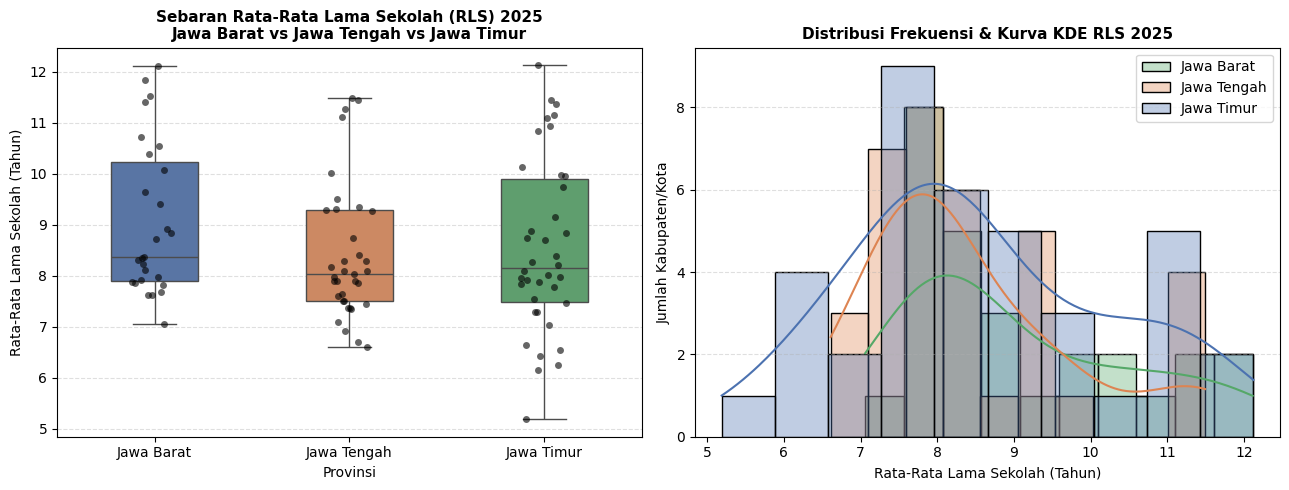

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan

# ==============================================================================
# 1. LOAD & PEMBERSIHAN DATA BPS (JATIM, JATENG, JABAR 2025)
# ==============================================================================
# A. Jawa Timur (38 kab/kota)
df_jatim = pd.read_csv(
    "rls_jatim_2025.csv",
    skiprows=3,
    header=None,
    names=["kabupaten_kota", "rls"],
)
df_jatim["kabupaten_kota"] = df_jatim["kabupaten_kota"].str.strip()
df_jatim = df_jatim[df_jatim["kabupaten_kota"] != "Jawa Timur"].copy()
df_jatim["provinsi"] = "Jawa Timur"

# B. Jawa Tengah (35 kab/kota)
df_jateng = pd.read_csv(
    "rls_jateng_2025.csv",
    skiprows=3,
    header=None,
    names=["kabupaten_kota", "rls"],
)
df_jateng["kabupaten_kota"] = df_jateng["kabupaten_kota"].str.strip()
df_jateng = df_jateng[
    ~df_jateng["kabupaten_kota"].str.contains("Provinsi Jawa Tengah")
].copy()
df_jateng["provinsi"] = "Jawa Tengah"

# C. Jawa Barat (27 kab/kota - dari file grid-export yang di-rename ke rls_jabar_2025.csv)
df_jabar_raw = pd.read_csv("rls_jabar_2025.csv")
df_jabar = df_jabar_raw[["Wilayah", "Tahun2025"]].rename(
    columns={"Wilayah": "kabupaten_kota", "Tahun2025": "rls"}
)
df_jabar["kabupaten_kota"] = df_jabar["kabupaten_kota"].str.strip()
df_jabar = df_jabar[df_jabar["kabupaten_kota"] != "Provinsi Jawa Barat"].copy()
df_jabar["provinsi"] = "Jawa Barat"

# Gabungkan ketiga provinsi (total 100 kab/kota)
df = pd.concat([df_jatim, df_jateng, df_jabar], ignore_index=True)
df["rls"] = pd.to_numeric(df["rls"])

# ==============================================================================
# 2. STATISTIK DESKRIPTIF PER PROVINSI
# ==============================================================================
desc = (
    df.groupby("provinsi")["rls"]
    .agg(
        jumlah_wilayah="count",
        mean="mean",
        median="median",
        std_dev="std",
        min="min",
        max="max",
    )
    .round(4)
)
print("=== STATISTIK DESKRIPTIF RLS 2025 (TAHUN) ===")
print(desc, "\n")

# ==============================================================================
# 3. UJI NORMALITAS MASING-MASING PROVINSI (ALPHA = 0.05)
# ==============================================================================
print("=== UJI NORMALITAS (ALPHA = 0.05) ===")
for prov, group in df.groupby("provinsi"):
  sw_stat, sw_p = stats.shapiro(group["rls"])
  ks_stat, ks_p = stats.kstest(
      group["rls"], "norm", args=(group["rls"].mean(), group["rls"].std(ddof=1))
  )
  status = "Normal" if sw_p > 0.05 else "Tidak Normal"
  print(
      f"{prov} (n={len(group)}): "
      f"Shapiro-Wilk W={sw_stat:.4f}, p={sw_p:.4f} ({status}) | "
      f"KS D={ks_stat:.4f}, p={ks_p:.4f}"
  )

# ==============================================================================
# 4. UJI HETEROSKEDASTISITAS ANTAR-3 PROVINSI (ALPHA = 0.05)
# ==============================================================================
groups = [g["rls"].values for _, g in df.groupby("provinsi")]
lev_med_stat, lev_med_p = stats.levene(*groups, center="median")
lev_mean_stat, lev_mean_p = stats.levene(*groups, center="mean")
bart_stat, bart_p = stats.bartlett(*groups)

model = smf.ols("rls ~ C(provinsi)", data=df).fit()
bp_lm, bp_lm_p, _, _ = het_breuschpagan(model.resid, model.model.exog)

print("\n=== UJI HETEROSKEDASTISITAS (ALPHA = 0.05) ===")
print(
    f"Levene (Median / Brown-Forsythe) : stat={lev_med_stat:.4f},"
    f" p={lev_med_p:.4f} ->"
    f" {'Homoskedastik' if lev_med_p > 0.05 else 'Heteroskedastik'}"
)
print(
    f"Levene (Mean)                    : stat={lev_mean_stat:.4f},"
    f" p={lev_mean_p:.4f} ->"
    f" {'Homoskedastik' if lev_mean_p > 0.05 else 'Heteroskedastik'}"
)
print(
    f"Bartlett                         : stat={bart_stat:.4f}, p={bart_p:.4f}"
    f" -> {'Homoskedastik' if bart_p > 0.05 else 'Heteroskedastik'}"
)
print(
    f"Breusch-Pagan (OLS)              : LM={bp_lm:.4f}, p={bp_lm_p:.4f} ->"
    f" {'Homoskedastik' if bp_lm_p > 0.05 else 'Heteroskedastik'}\n"
)

# ==============================================================================
# 5. VISUALISASI SEBARAN DATA (3 PROVINSI)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order_prov = ["Jawa Barat", "Jawa Tengah", "Jawa Timur"]
palette_prov = ["#55A868", "#DD8452", "#4C72B0"]

sns.boxplot(
    data=df,
    x="provinsi",
    y="rls",
    hue="provinsi",
    order=order_prov,
    palette=palette_prov,
    legend=False,
    ax=axes[0],
    width=0.45,
)
sns.stripplot(
    data=df,
    x="provinsi",
    y="rls",
    order=order_prov,
    ax=axes[0],
    color="black",
    alpha=0.6,
    jitter=0.12,
)
axes[0].set_title(
    "Sebaran Rata-Rata Lama Sekolah (RLS) 2025\nJawa Barat vs Jawa Tengah vs"
    " Jawa Timur",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_xlabel("Provinsi")
axes[0].set_ylabel("Rata-Rata Lama Sekolah (Tahun)")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

for prov, color in zip(order_prov, palette_prov):
  sns.histplot(
      df[df["provinsi"] == prov]["rls"],
      kde=True,
      ax=axes[1],
      label=prov,
      color=color,
      alpha=0.35,
      bins=10,
  )

axes[1].set_title(
    "Distribusi Frekuensi & Kurva KDE RLS 2025", fontsize=11, fontweight="bold"
)
axes[1].set_xlabel("Rata-Rata Lama Sekolah (Tahun)")
axes[1].set_ylabel("Jumlah Kabupaten/Kota")
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("rls_3_provinsi_2025.png", dpi=150)
plt.show()